# Synthetic Dataset Ground Truth Analysis (v2)

Analyzes the `correlated_noise` synthetic benchmark where feature identities are known
exactly from `make_classification`.

Uses the **Broad** ground truth definition: informative + redundant features (indices 0..54),
which is appropriate for Boruta's *all-relevant* selection objective.

> This notebook imports all analysis logic from `analyze_synthetic_gt_functions.py`.
> Adjust the **Configuration** cell below, then run all cells.

## Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

import analyze_synthetic_gt_functions as ag

In [2]:
ag.apply_plot_theme(font_scale=1.2, dpi=110)

In [3]:
figures_dir = '../figures/synthetic_datasets'

## Configuration

In [4]:
# ── File paths ────────────────────────────────────────────────────────────
GT_FILE   = '../data/older/benchmark_gt_results_vGT.csv' 
MAIN_FILE = '../data/older/benchmark_results_vGT.csv'

# ── Filters ────────────────────────────────────────────────────────────────
TARGET_ESTIMATOR = 'extra_trees'
DATASET          = 'correlated_noise'
GT               = 'Broad'   # GT column suffix used throughout

# ── Single-alpha focus (used in '*b' single-alpha plots) ──────────────────
FOCUS_ALPHA = 0.01

## 1. Load Data

In [5]:
df_gt, df_main = ag.load_data(
    gt_file=GT_FILE,
    main_file=MAIN_FILE,
    dataset=DATASET,
    estimator=TARGET_ESTIMATOR,
)
df_gt.head()

GT log rows  : 942
Main log rows: 100
Methods      : ['Vanilla' 'GreedyParallel']
Alpha values : [1e-05, 0.0001, 0.001, 0.01, 0.1]
GT Broad size: 105


,Dataset,Task,n_samples,n_features_orig,Estimator,Method,Alpha,Run_ID,Checkpoint_ID,Iteration,...,F1_Strict,GT_Broad_Size,TP_Broad,FP_Broad,FN_Broad,TN_Broad,Precision_Broad,Recall_Broad,Specificity_Broad,F1_Broad
0,correlated_noise,class,1000,500,extra_trees,Vanilla,0.1,3,0,1,...,0.000000,105,0,0,105,395,0.0,0.000000,1.0,0.000000
1,correlated_noise,class,1000,500,extra_trees,Vanilla,0.1,3,1,13,...,0.102564,105,73,0,32,395,1.0,0.695238,1.0,0.820225
2,correlated_noise,class,1000,500,extra_trees,Vanilla,0.1,3,2,17,...,0.117647,105,80,0,25,395,1.0,0.761905,1.0,0.864865
3,correlated_noise,class,1000,500,extra_trees,Vanilla,0.1,3,3,21,...,0.114943,105,82,0,23,395,1.0,0.780952,1.0,0.877005
4,correlated_noise,class,1000,500,extra_trees,Vanilla,0.1,3,4,24,...,0.108696,105,87,0,18,395,1.0,0.828571,1.0,0.906250


## 2. Data Preparation

In [6]:
ctx = ag.prepare_data(df_gt, gt_label=GT)

# Unpack context for convenience
df_vanilla       = ctx['df_vanilla']
df_greedy        = ctx['df_greedy']
df_vanilla_final = ctx['df_vanilla_final']
df_greedy_final  = ctx['df_greedy_final']
greedy_label     = ctx['greedy_label']
alphas           = ctx['alphas']
n_features       = ctx['n_features']
gt_broad         = ctx['gt_broad']

Vanilla checkpoints      : 892
Vanilla final-state rows : 50
GreedyParallel snapshots : 50
Alpha values: [1e-05, 0.0001, 0.001, 0.01, 0.1]
n_features=500, GT broad=105


## 3. Final-State Summary Table

In [7]:
df_final_summary = ag.build_final_summary_table(
    df_vanilla_final, df_greedy_final,
    alphas=alphas, GT=GT, greedy_label=greedy_label,
)

Final-state metrics — Broad GT (mean ± std across runs):


Metric                 Recall  Precision  Specificity     F1
Method         Alpha                                        
GreedyParallel 0.0001   0.971      0.914        0.975  0.941
               0.001    0.970      0.921        0.978  0.944
               0.01     0.965      0.932        0.981  0.948
               0.1      0.959      0.936        0.982  0.947
               1e-05    0.972      0.914        0.975  0.942
Vanilla        0.0001   0.884      0.989        0.997  0.934
               0.001    0.890      0.989        0.997  0.937
               0.01     0.895      0.989        0.997  0.940
               0.1      0.891      0.989        0.997  0.938
               1e-05    0.880      0.989        0.997  0.931

## 4. Final-State Barplot — All Metrics

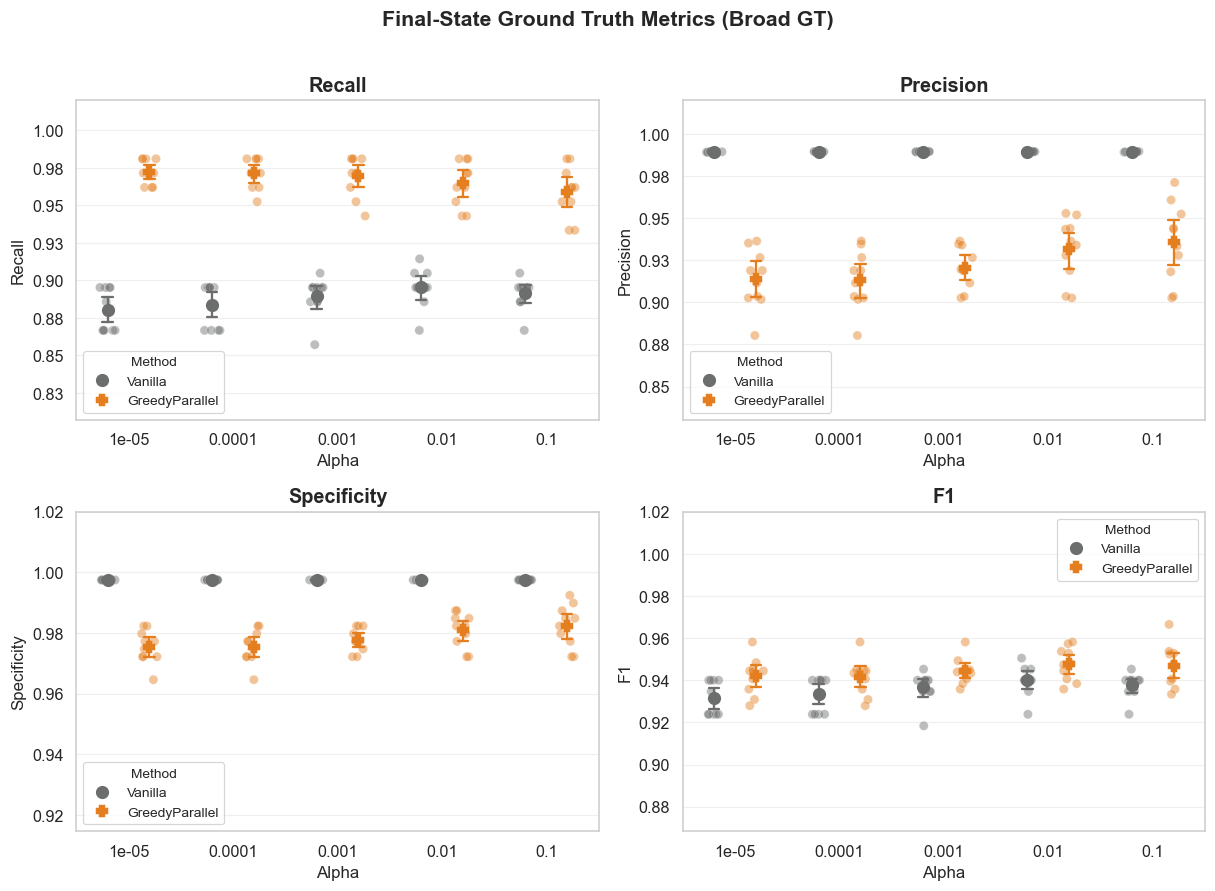

In [8]:
ag.plot_final_state_barplot(
    df_vanilla_final, df_greedy_final,
    alphas=alphas, GT=GT, greedy_label=greedy_label,
    dataset=DATASET, estimator=TARGET_ESTIMATOR,
    figures_dir=figures_dir,
)

### 4b. Statistical Tests — Final-State Metrics

Three Welch t-tests per (metric, alpha) pair:
- **Two-sided**: detects any difference between methods.
- **One-sided Greedy > Vanilla**: tests whether Greedy is strictly higher.
- **One-sided Vanilla > Greedy**: tests whether Vanilla is strictly higher.

Significance codes: `***` p<0.001 · `**` p<0.01 · `*` p<0.05 · `ns` not significant.

In [9]:
df_greedy_final[df_greedy_final['Alpha'] == 0.01]['Iteration'].mean()

-1.0

In [10]:
df_barplot_tests = ag.run_statistical_tests(
    df_vanilla_final, df_greedy_final,
    alphas=alphas, GT=GT, greedy_label=greedy_label,
)

Statistical comparison — Broad GT (Welch t-test, significance = 0.05)
Columns: P_TwoSided (any diff) | P_Greedy>Vanilla (one-sided) | P_Vanilla>Greedy (one-sided)
--------------------------------------------------------------------------------------------------------------


,Metric,Alpha,Vanilla_Mean,Greedy_Mean,Diff (V-G),P_TwoSided,Sig_Two,P_Greedy>Vanilla,Sig_G>V,P_Vanilla>Greedy,Sig_V>G,Winner
0,Recall,1e-05,0.8800,0.9724,-0.0924,0.0000,***,0.0000,***,1.0000,ns,GreedyParallel
1,Recall,0.0001,0.8838,0.9714,-0.0876,0.0000,***,0.0000,***,1.0000,ns,GreedyParallel
2,Recall,0.001,0.8895,0.9695,-0.0800,0.0000,***,0.0000,***,1.0000,ns,GreedyParallel
3,Recall,0.01,0.8952,0.9648,-0.0695,0.0000,***,0.0000,***,1.0000,ns,GreedyParallel
4,Recall,0.1,0.8914,0.9590,-0.0676,0.0000,***,0.0000,***,1.0000,ns,GreedyParallel
5,Precision,1e-05,0.9893,0.9136,0.0757,0.0000,***,1.0000,ns,0.0000,***,Vanilla
6,Precision,0.0001,0.9893,0.9135,0.0758,0.0000,***,1.0000,ns,0.0000,***,Vanilla
7,Precision,0.001,0.9894,0.9207,0.0687,0.0000,***,1.0000,ns,0.0000,***,Vanilla
8,Precision,0.01,0.9895,0.9315,0.0579,0.0000,***,1.0000,ns,0.0000,***,Vanilla
9,Precision,0.1,0.9894,0.9357,0.0537,0.0000,***,1.0000,ns,0.0000,***,Vanilla


## 5. Confusion Breakdown at Final State

TP / FP / FN / TN counts show *how* selections are wrong — false alarms vs misses.

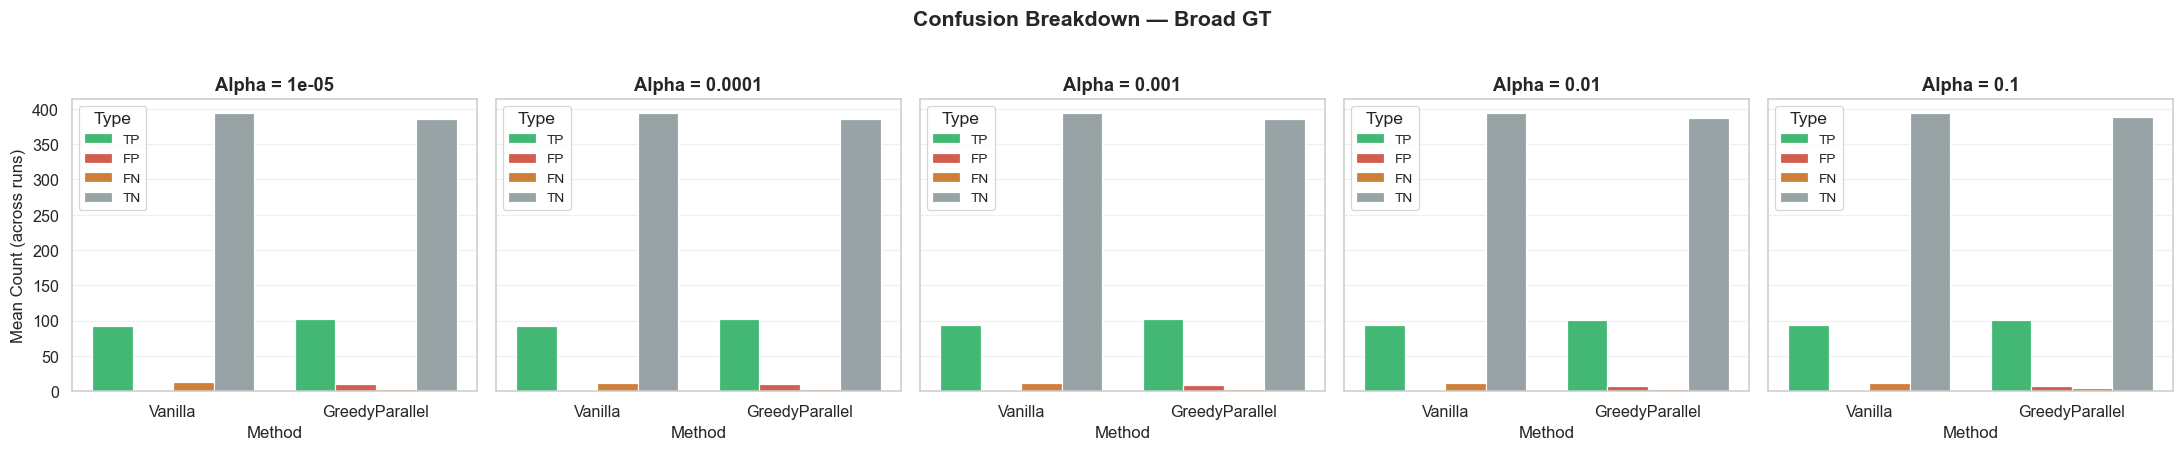

In [11]:
ag.plot_confusion_breakdown(
    df_vanilla_final, df_greedy_final,
    alphas=alphas, GT=GT, greedy_label=greedy_label,
    dataset=DATASET, estimator=TARGET_ESTIMATOR,
    figures_dir=figures_dir,
)

## 6. Convergence Trajectories vs Iteration (Vanilla)

Each line is one run. Dashed line = GreedyParallel final mean.

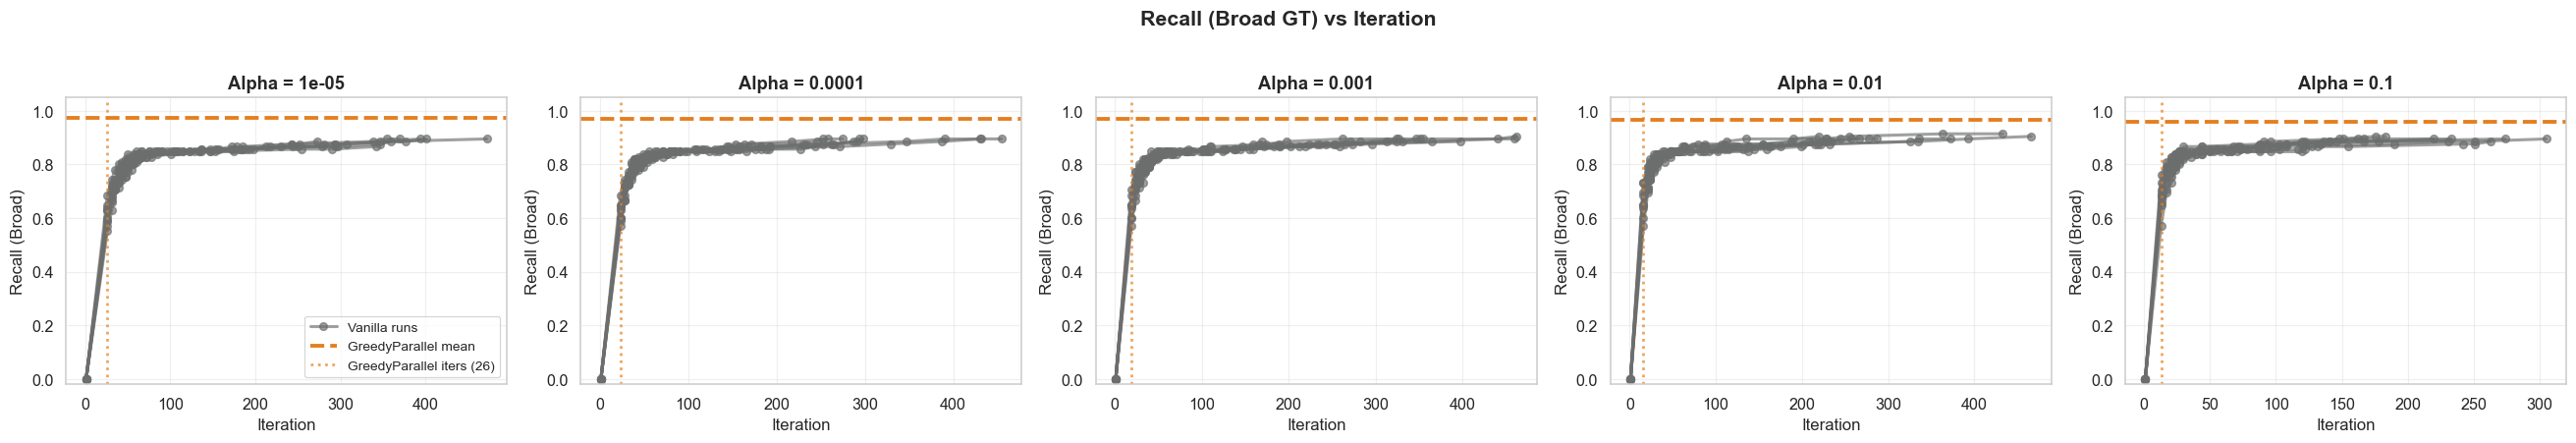

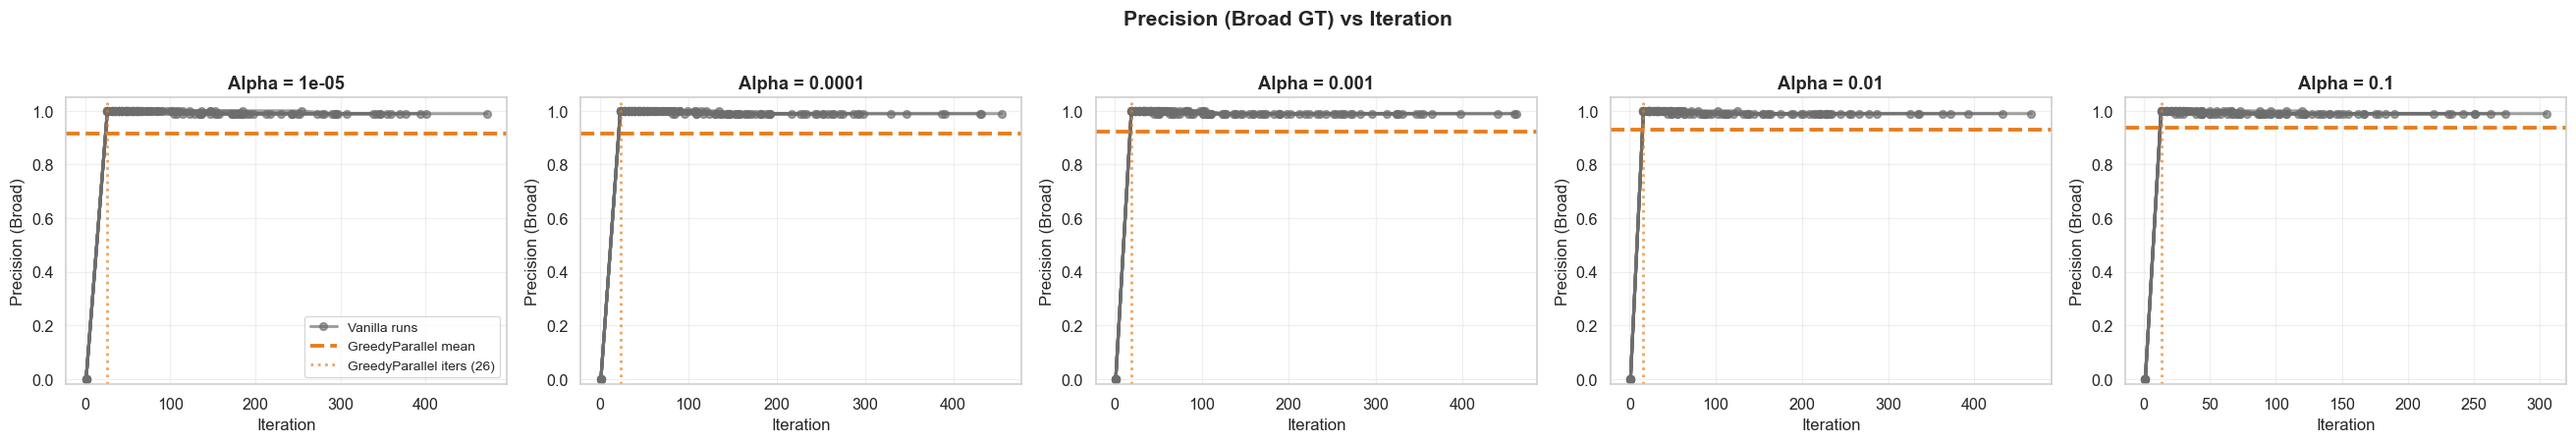

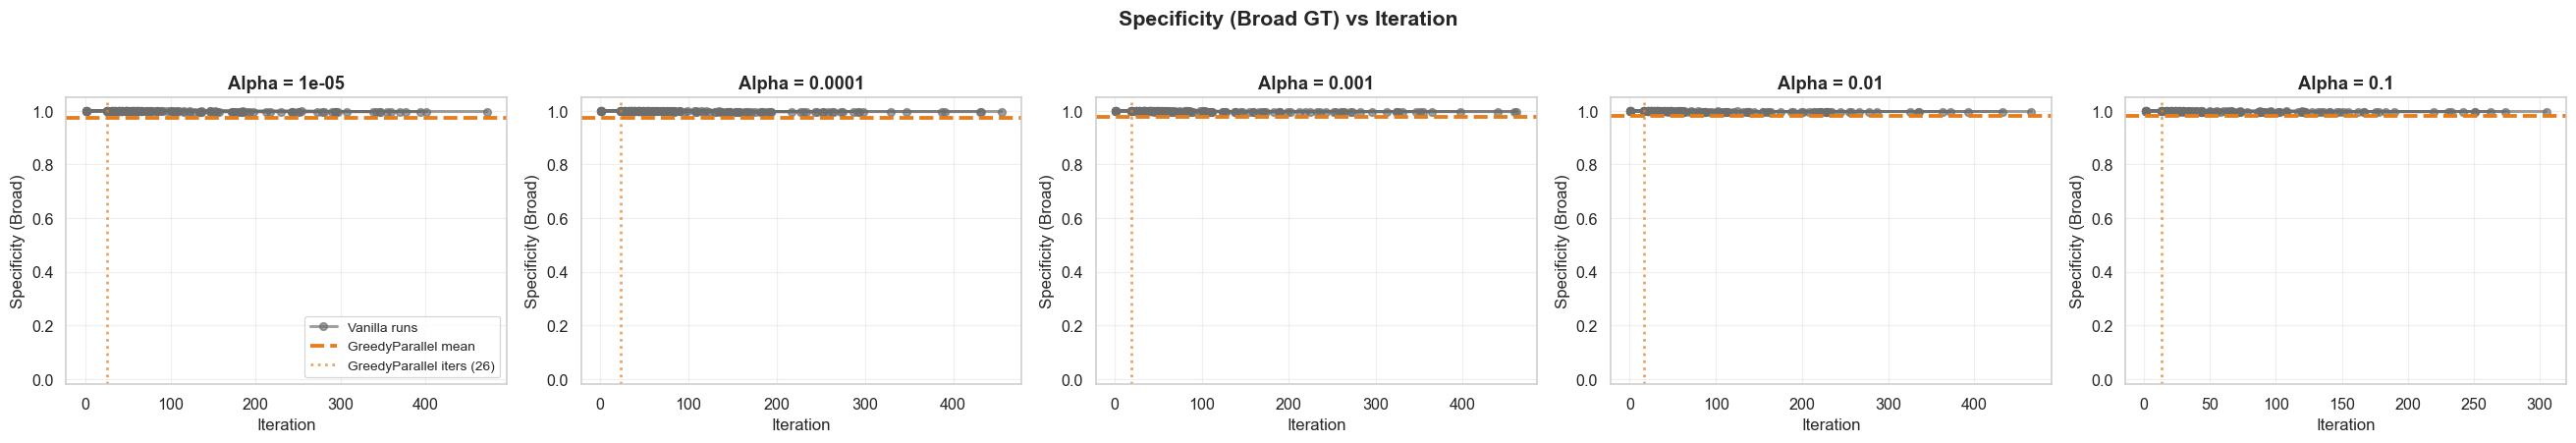

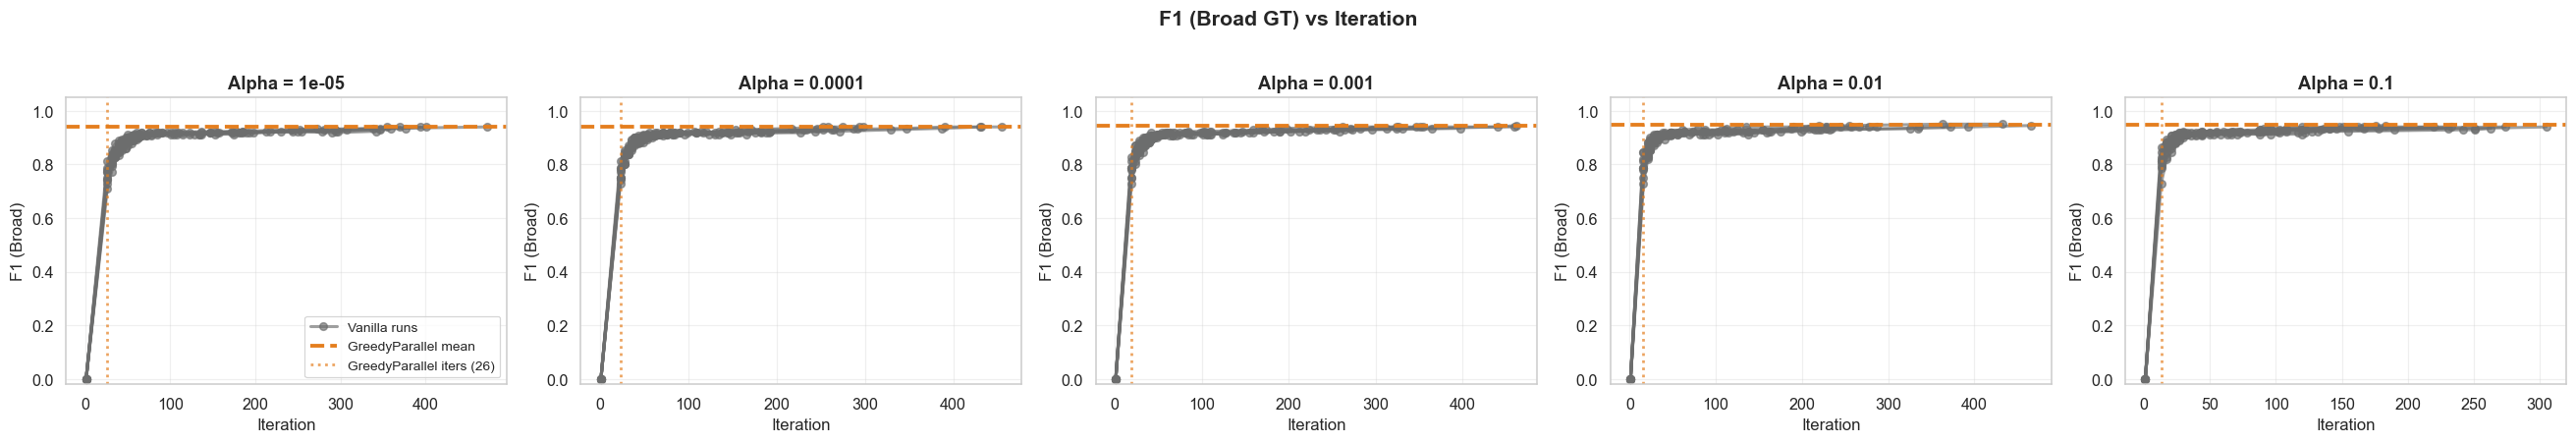

In [12]:
for metric in ['Recall', 'Precision', 'Specificity', 'F1']:
    ag.plot_metric_trajectories(
        metric,
        df_vanilla=df_vanilla, df_greedy=df_greedy,
        alphas=alphas, n_features=n_features,
        GT=GT, greedy_label=greedy_label,
        dataset=DATASET, estimator=TARGET_ESTIMATOR,
        x_col='Iteration', x_label='Iteration',
        figures_dir=figures_dir,
    )

## 6b. Convergence Trajectories — Single Alpha (Iteration)

All four metrics for `FOCUS_ALPHA` in one 2×2 figure.

In [13]:
greedy_x = ag._greedy_iterations(0.01, 500)
greedy_x

16

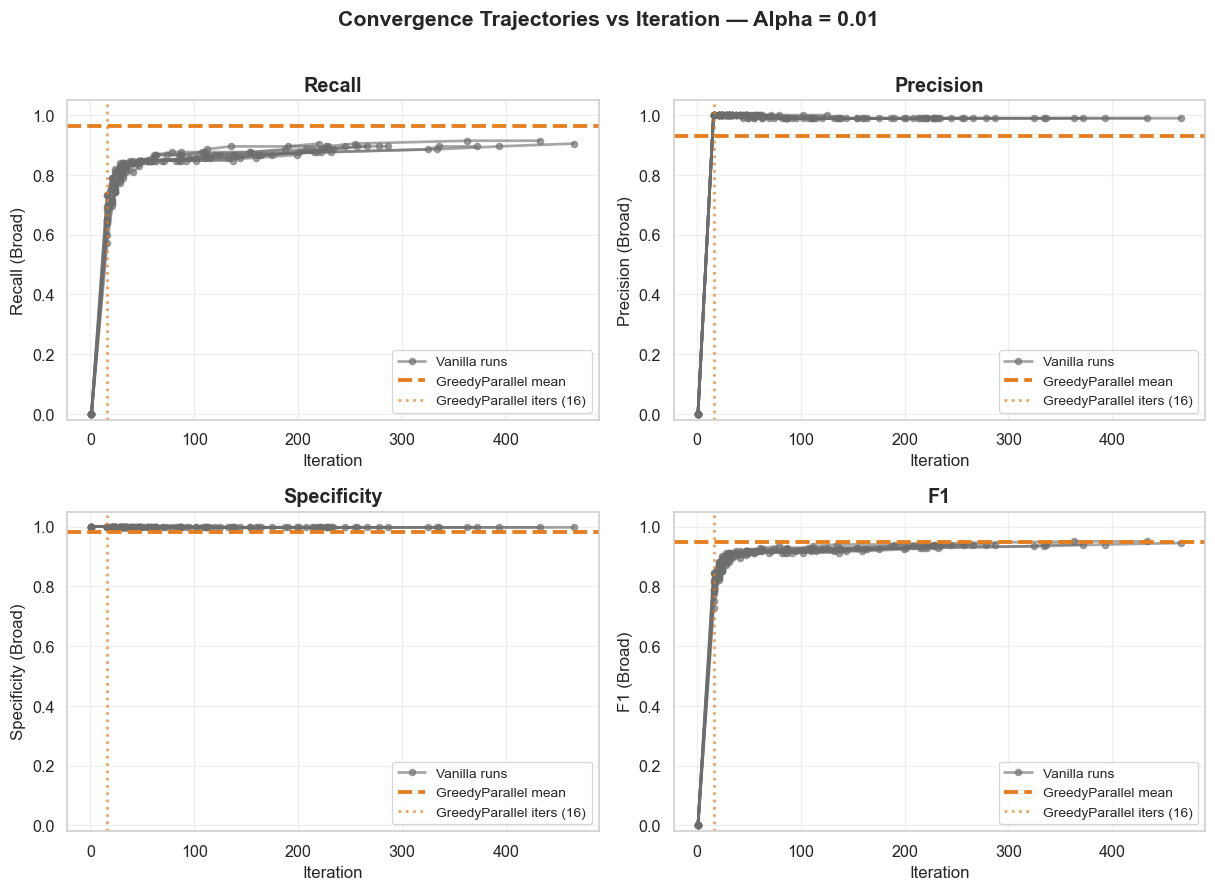

In [14]:
ag.plot_convergence_single_alpha_iteration(
    focus_alpha=FOCUS_ALPHA,
    df_vanilla=df_vanilla, df_greedy=df_greedy,
    n_features=n_features,
    GT=GT, greedy_label=greedy_label,
    dataset=DATASET, estimator=TARGET_ESTIMATOR,
    figures_dir=figures_dir,
)

## 7. Convergence Trajectories vs Elapsed Time

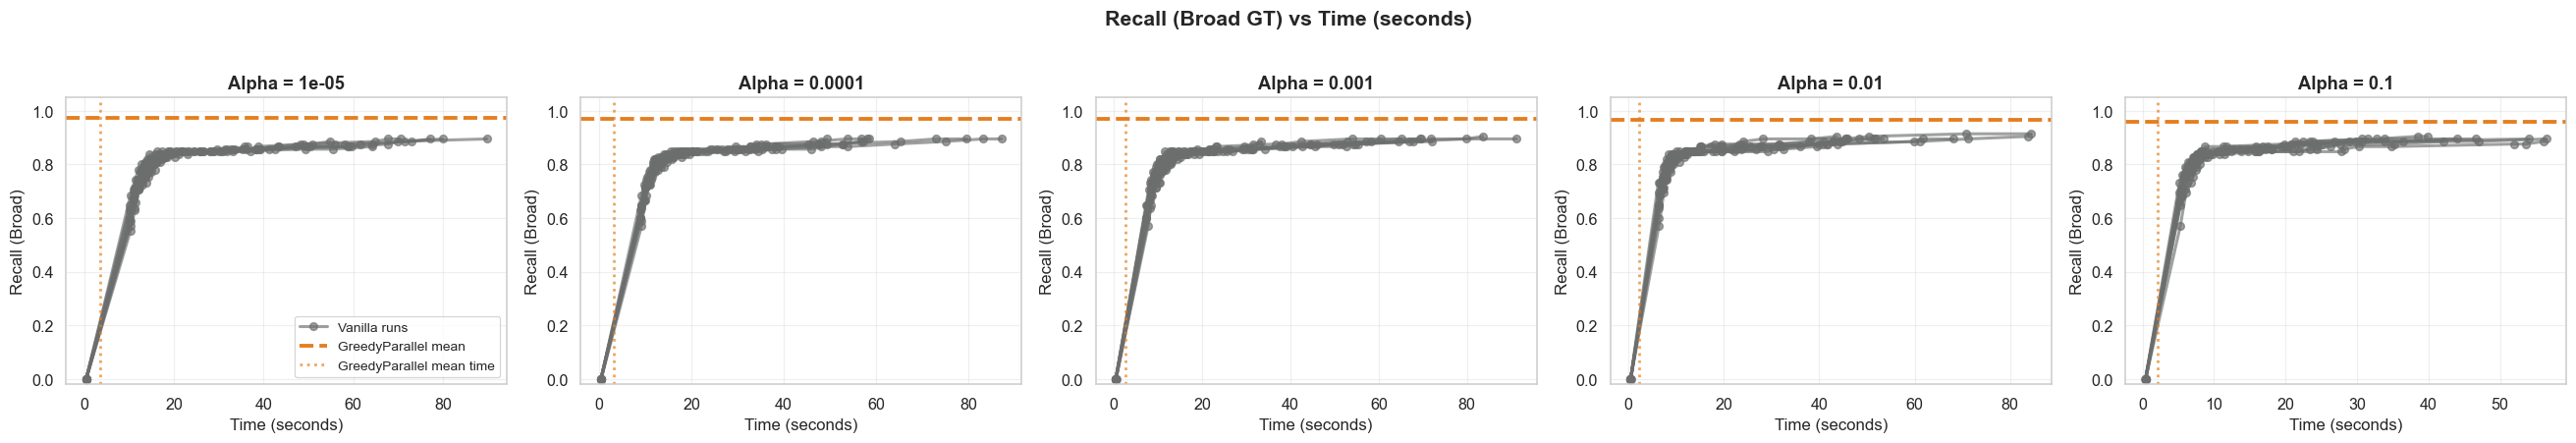

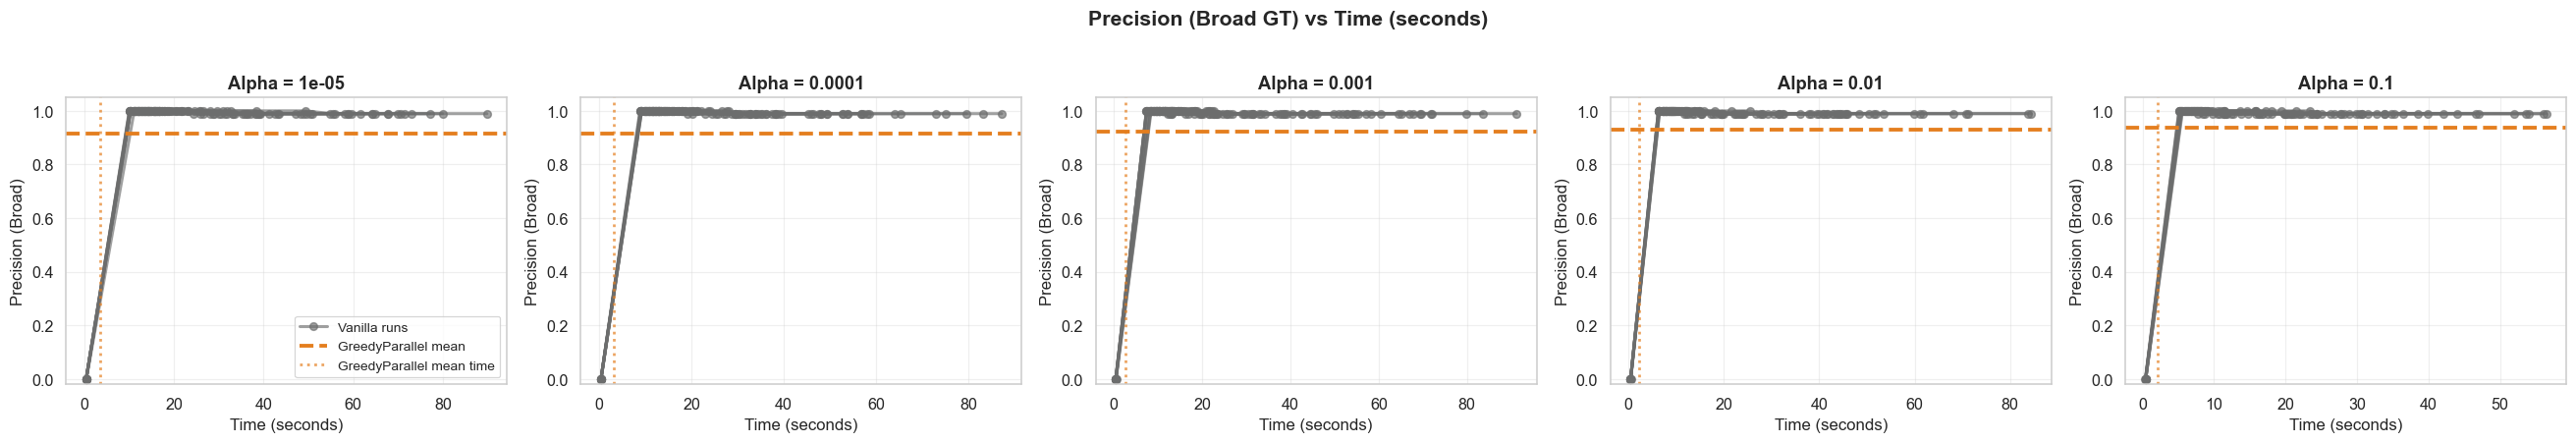

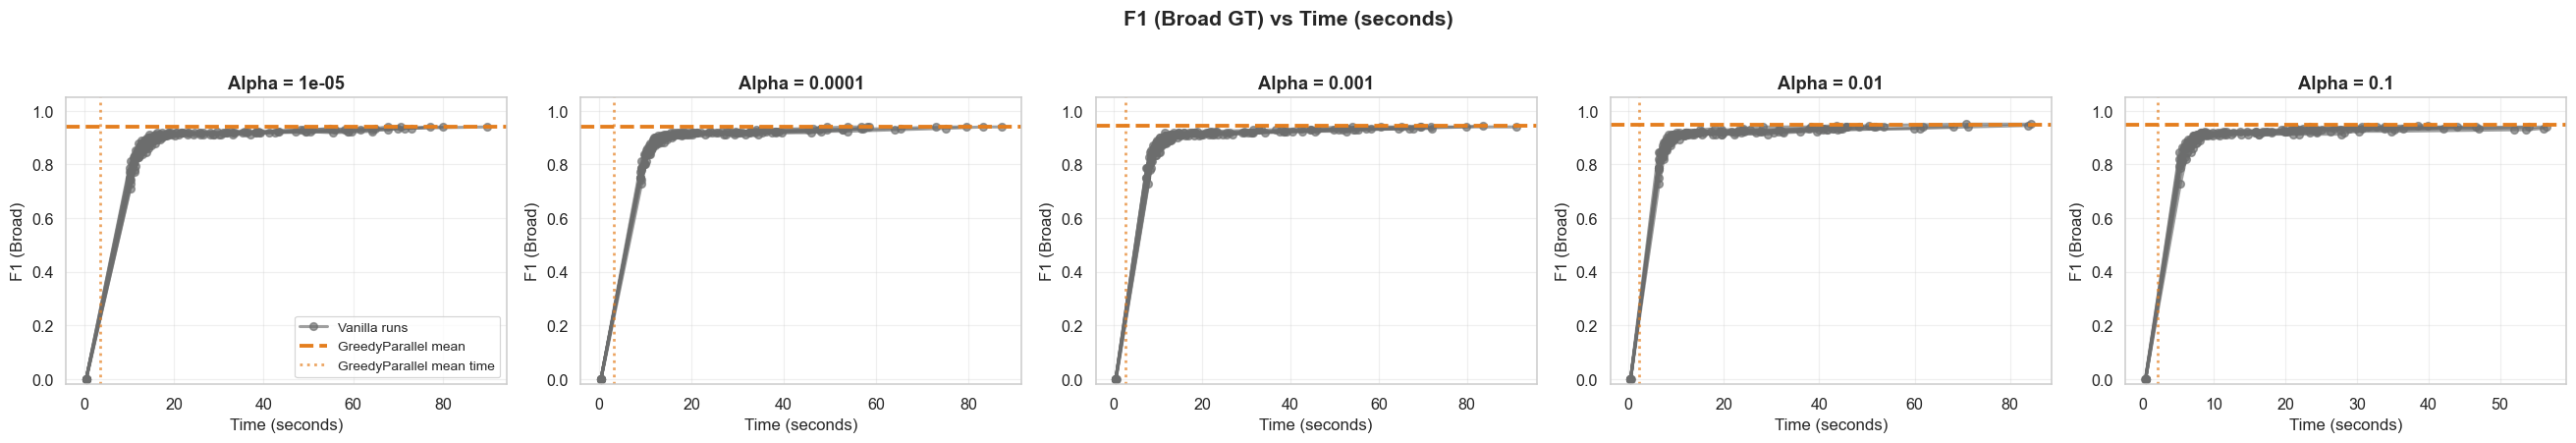

In [15]:
for metric in ['Recall', 'Precision', 'F1']:
    ag.plot_metric_trajectories(
        metric,
        df_vanilla=df_vanilla, df_greedy=df_greedy,
        alphas=alphas, n_features=n_features,
        GT=GT, greedy_label=greedy_label,
        dataset=DATASET, estimator=TARGET_ESTIMATOR,
        x_col='Elapsed_Sec', x_label='Time (seconds)',
        figures_dir=figures_dir,
    )

## 7b. Convergence Trajectories — Single Alpha (Time)

All four metrics for `FOCUS_ALPHA`, x-axis in elapsed seconds.

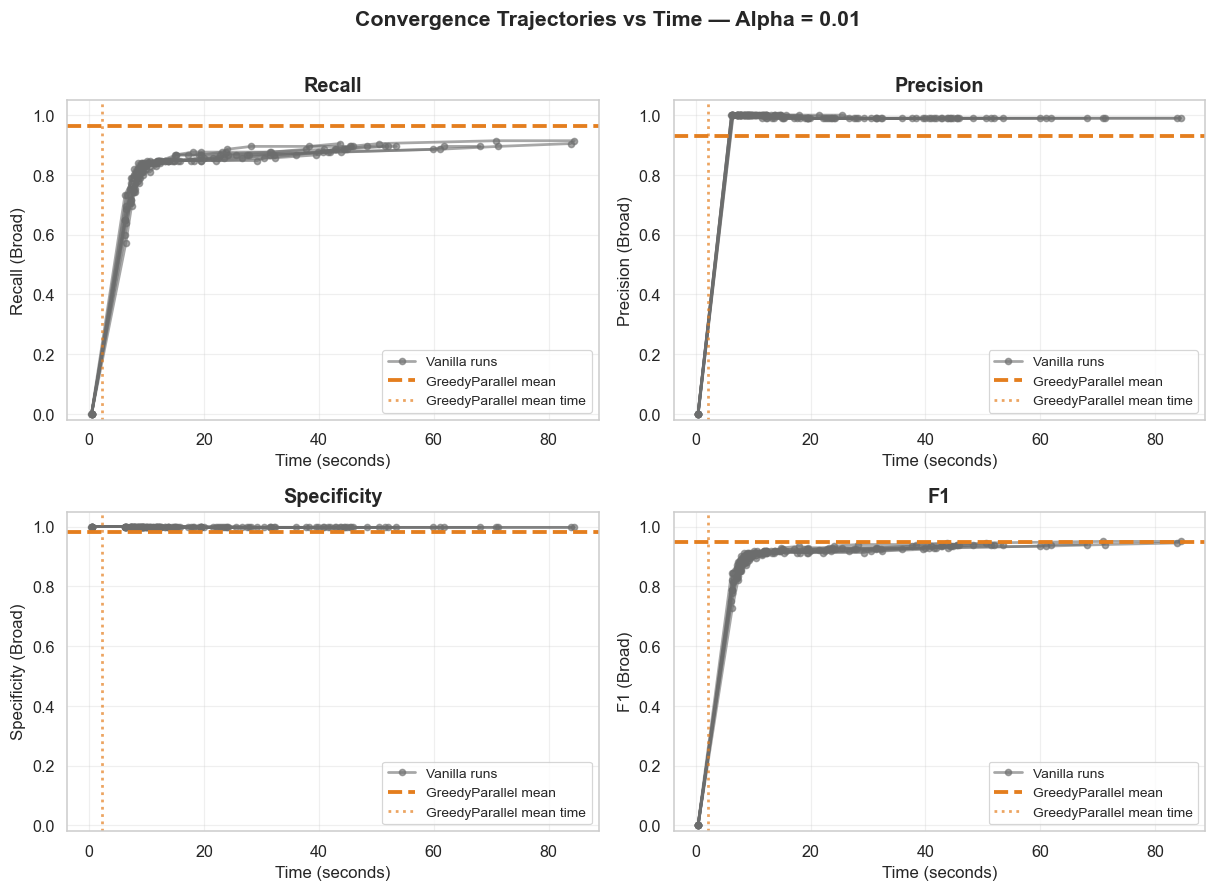

In [16]:
ag.plot_convergence_single_alpha_time(
    focus_alpha=FOCUS_ALPHA,
    df_vanilla=df_vanilla, df_greedy=df_greedy,
    GT=GT, greedy_label=greedy_label,
    dataset=DATASET, estimator=TARGET_ESTIMATOR,
    figures_dir=figures_dir,
)

## 8. Recall–Precision Path (Broad GT)

Phase-space view of each Vanilla run's trajectory.  
Square = start, star = end. Pentagon = GreedyParallel mean. Ideal target: top-right corner (1, 1).

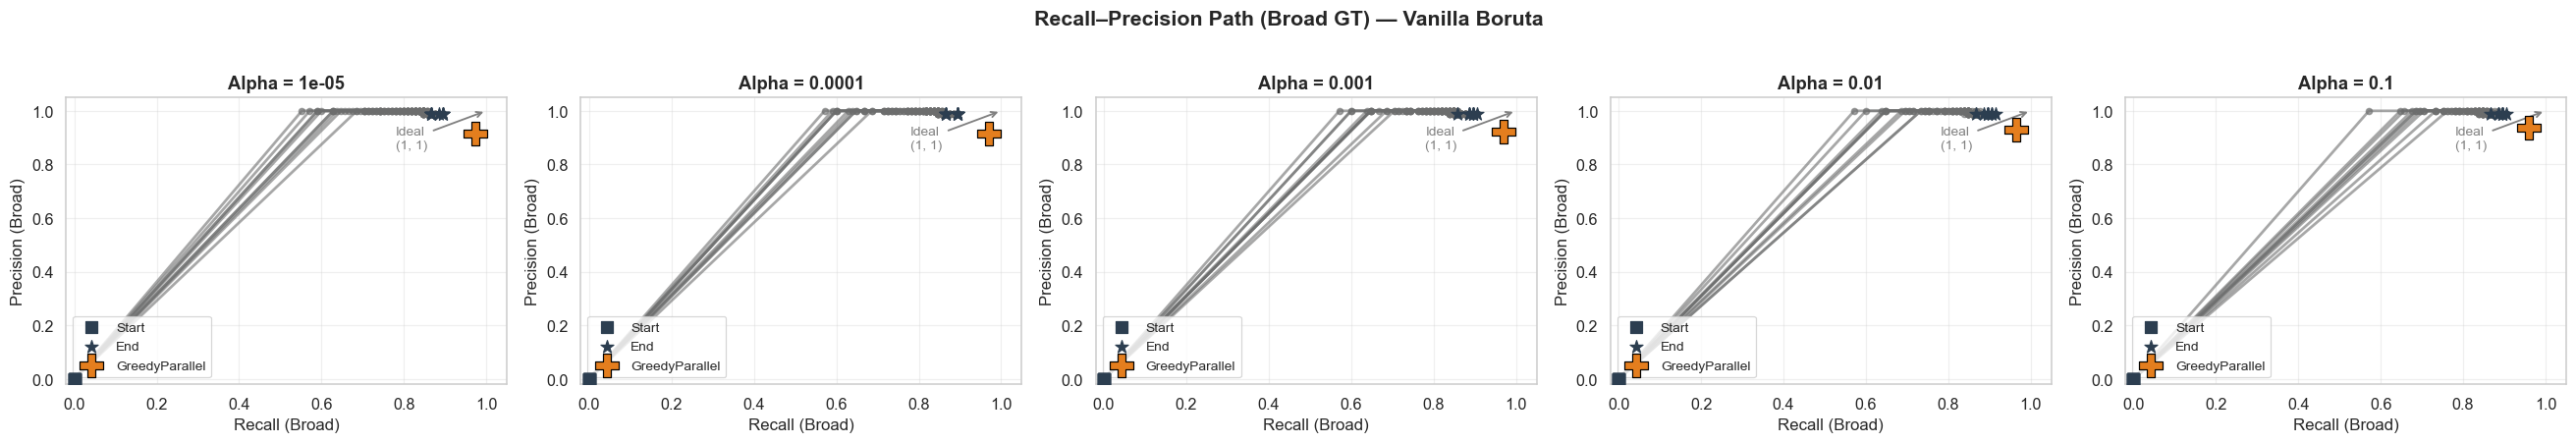

In [17]:
ag.plot_recall_precision_paths(
    df_vanilla=df_vanilla, df_greedy=df_greedy,
    alphas=alphas, GT=GT, greedy_label=greedy_label,
    dataset=DATASET, estimator=TARGET_ESTIMATOR,
    figures_dir=figures_dir,
)

## 8b. Recall–Precision Path — Single Alpha

Phase-space trajectories for `FOCUS_ALPHA` only.

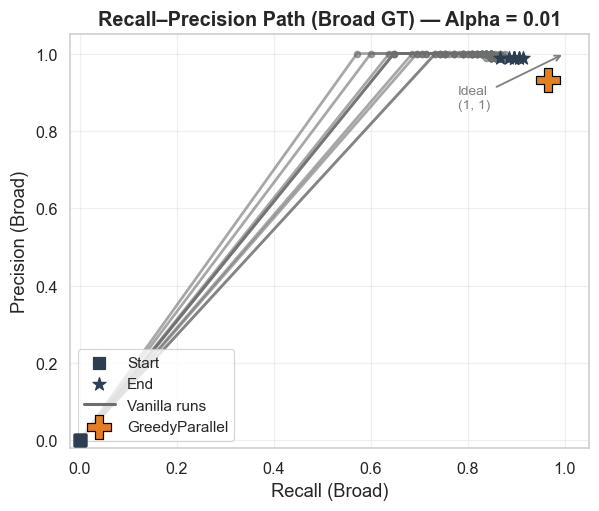

In [18]:
ag.plot_recall_precision_single_alpha(
    focus_alpha=FOCUS_ALPHA,
    df_vanilla=df_vanilla, df_greedy=df_greedy,
    GT=GT, greedy_label=greedy_label,
    dataset=DATASET, estimator=TARGET_ESTIMATOR,
    figures_dir=figures_dir,
)

## 9. Feature Count Trajectories (Confirmed / Tentative / Rejected)

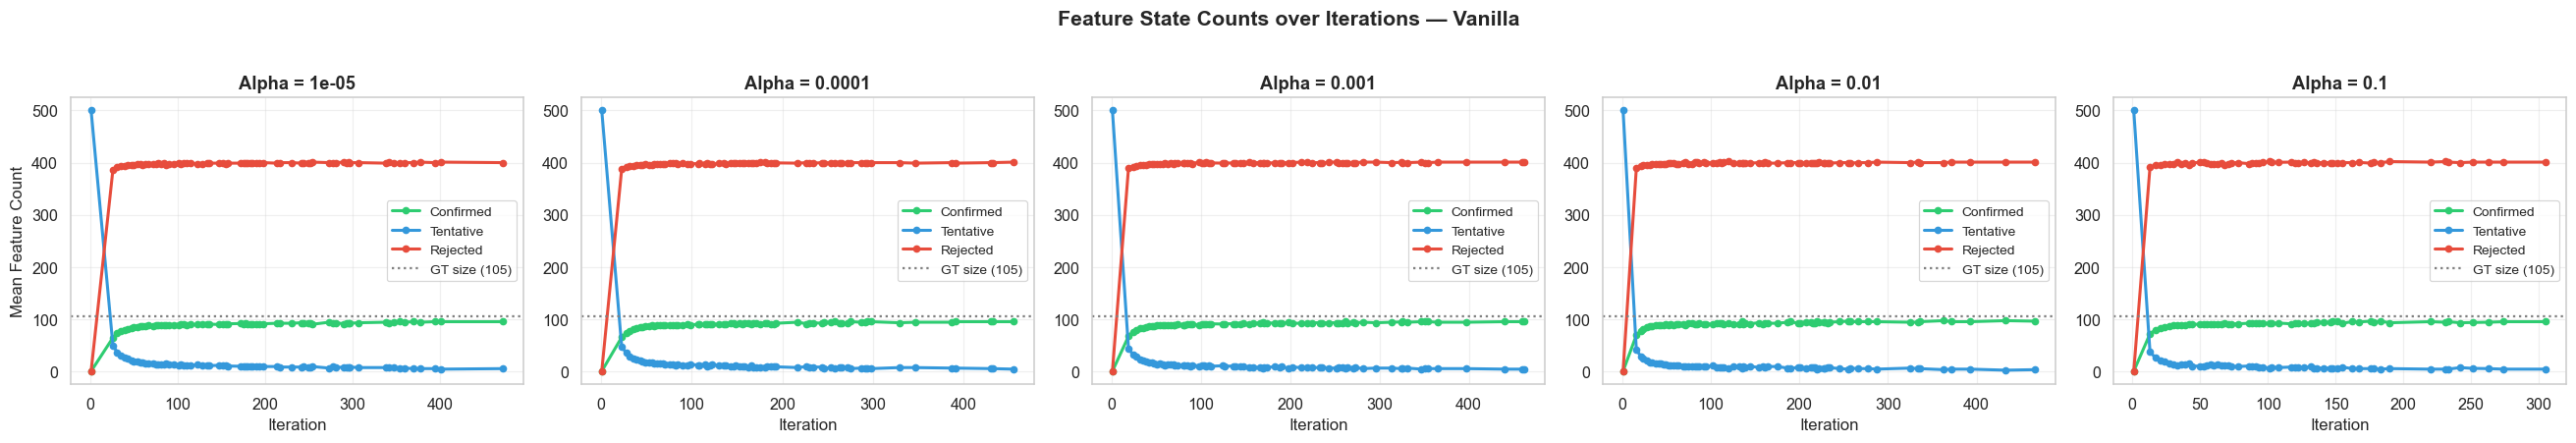

In [19]:
ag.plot_feature_count_trajectories(
    df_vanilla=df_vanilla,
    alphas=alphas, gt_broad=gt_broad,
    dataset=DATASET, estimator=TARGET_ESTIMATOR,
    figures_dir=figures_dir,
)

## 9b. Feature Count Trajectories — Single Alpha

Mean Confirmed / Tentative / Rejected counts for `FOCUS_ALPHA`.

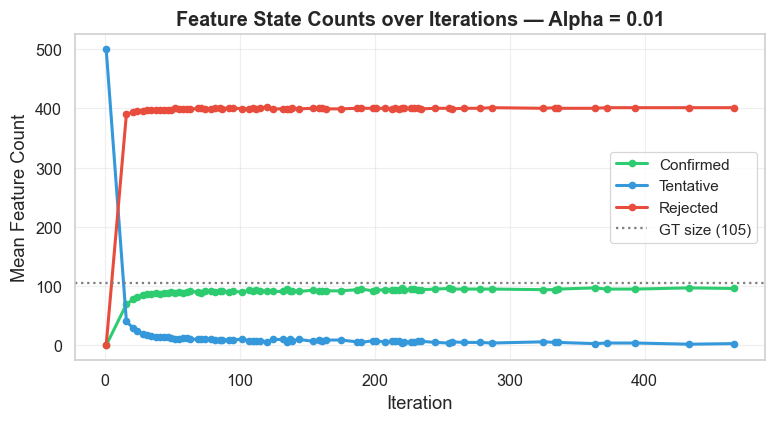

In [20]:
ag.plot_feature_count_single_alpha(
    focus_alpha=FOCUS_ALPHA,
    df_vanilla=df_vanilla, gt_broad=gt_broad,
    dataset=DATASET, estimator=TARGET_ESTIMATOR,
    figures_dir=figures_dir,
)

## 10. Undecidedness Factor & Potential Miss Rate (Vanilla)

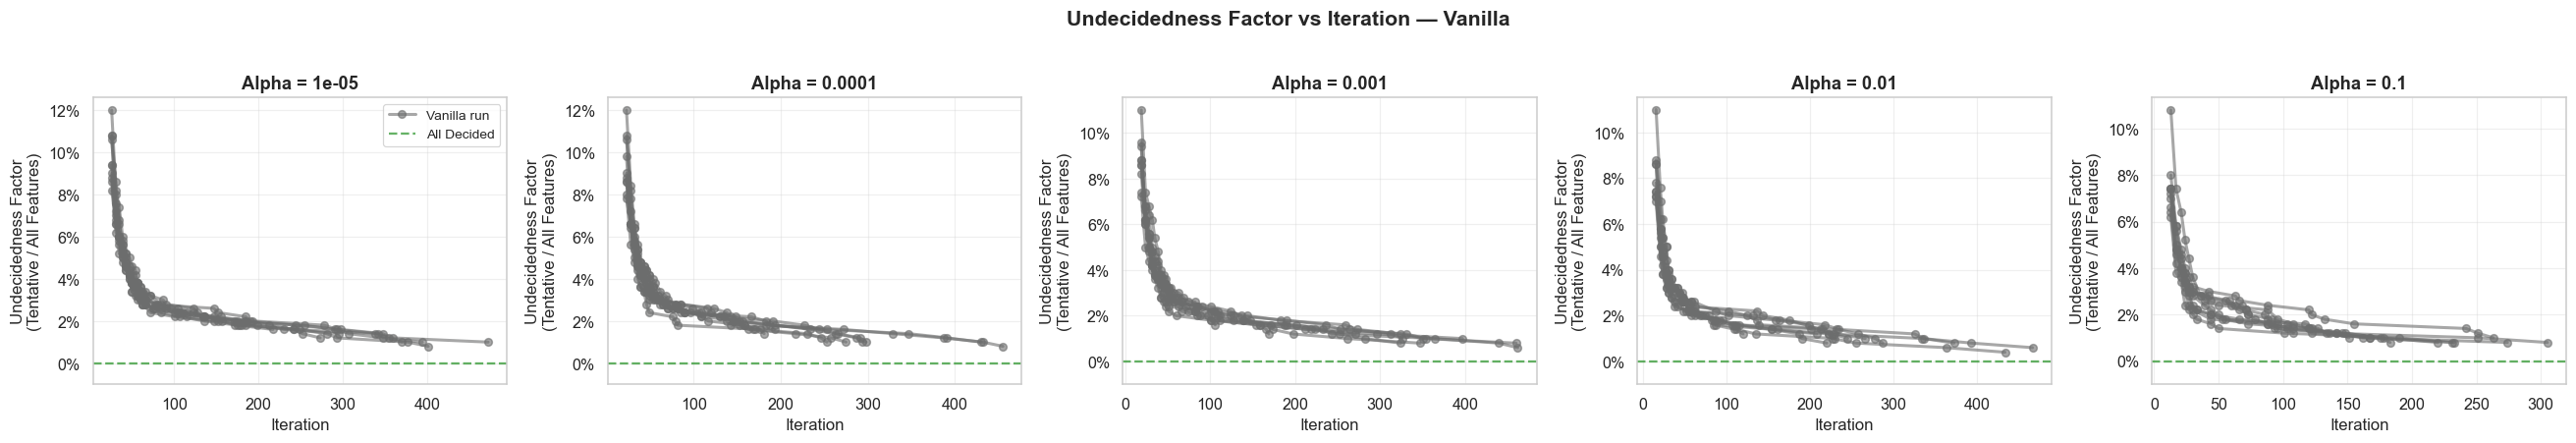

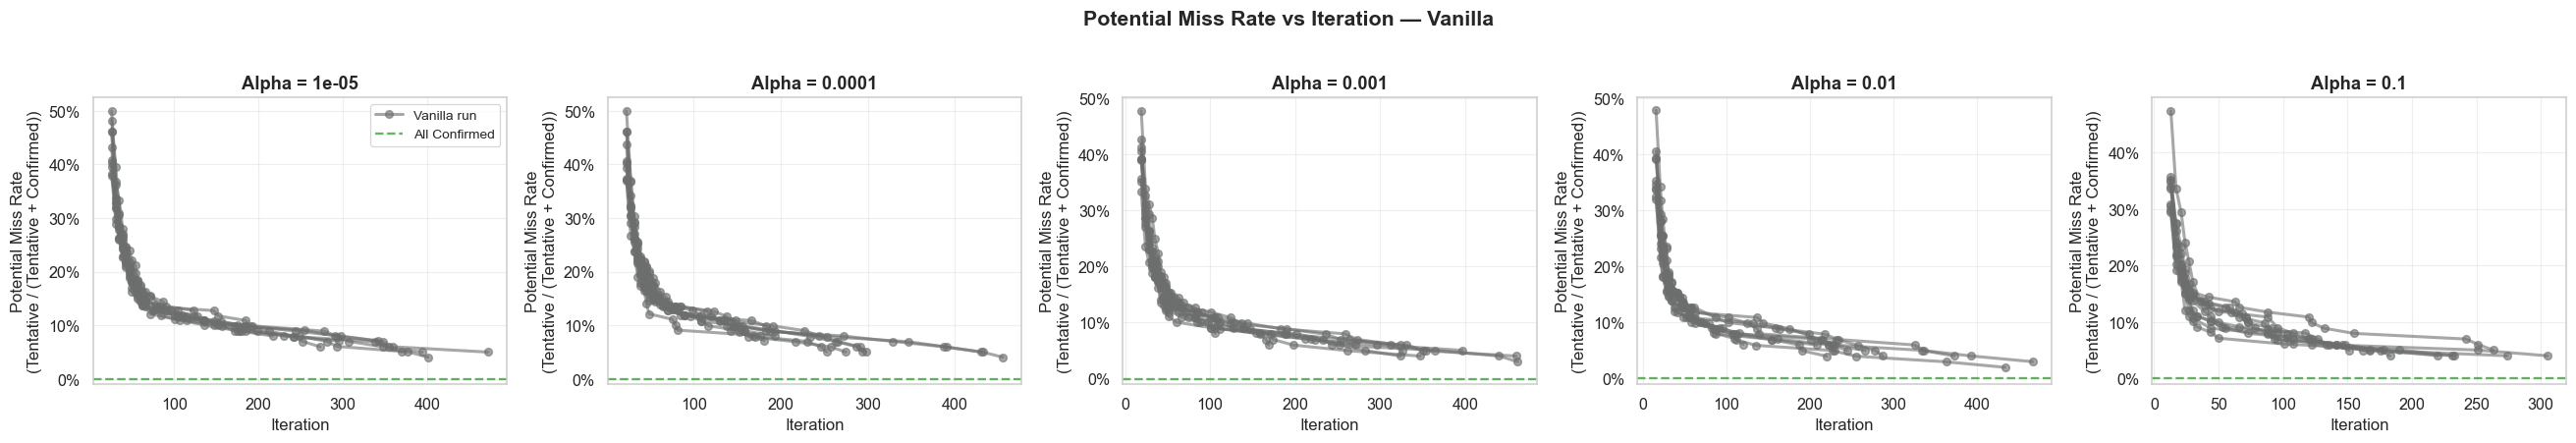

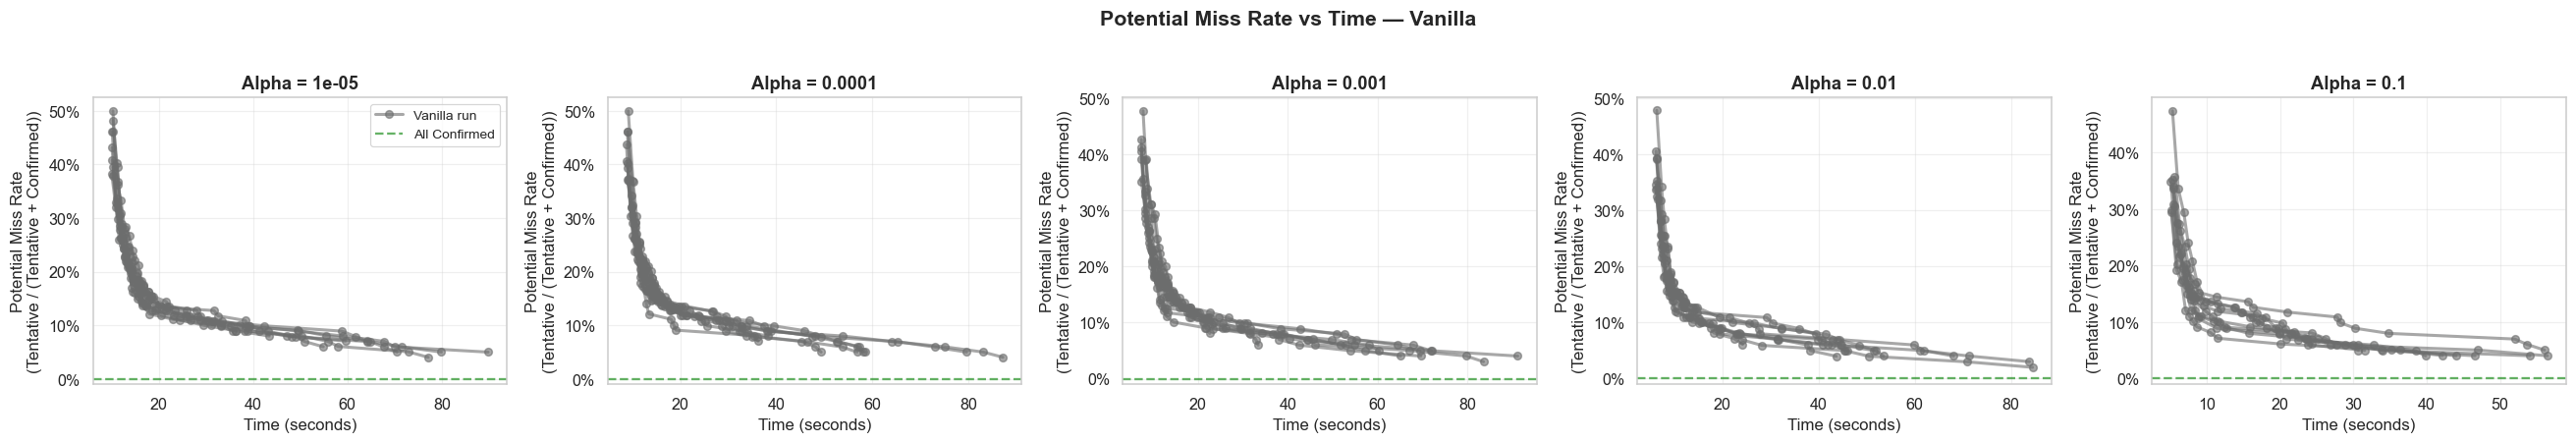

In [21]:
ag.plot_undecidedness_factor(
    df_vanilla=df_vanilla, alphas=alphas,
    dataset=DATASET, estimator=TARGET_ESTIMATOR,
    x_axis='iteration', figures_dir=figures_dir,
)
ag.plot_potential_miss_rate(
    df_vanilla=df_vanilla, alphas=alphas,
    dataset=DATASET, estimator=TARGET_ESTIMATOR,
    x_axis='iteration', figures_dir=figures_dir,
)
ag.plot_potential_miss_rate(
    df_vanilla=df_vanilla, alphas=alphas,
    dataset=DATASET, estimator=TARGET_ESTIMATOR,
    x_axis='time', figures_dir=figures_dir,
)

## 10b. Undecidedness & Potential Miss Rate — Single Alpha

Both diagnostic metrics for `FOCUS_ALPHA` side by side.

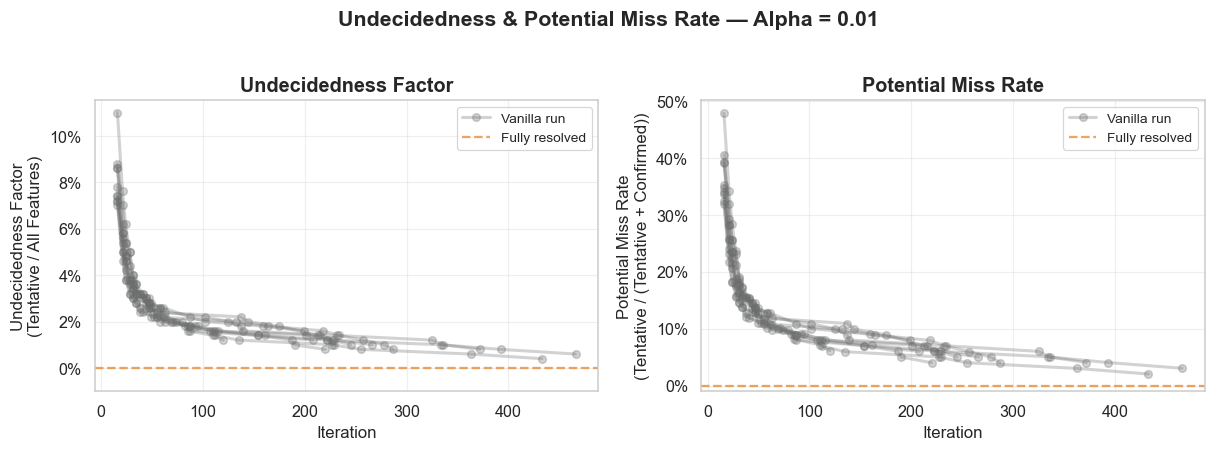

In [22]:
ag.plot_undecidedness_single_alpha(
    focus_alpha=FOCUS_ALPHA,
    df_vanilla=df_vanilla,
    dataset=DATASET, estimator=TARGET_ESTIMATOR,
    figures_dir=figures_dir,
)

## 11. Heatmap: Final F1 (Broad) by Method × Alpha

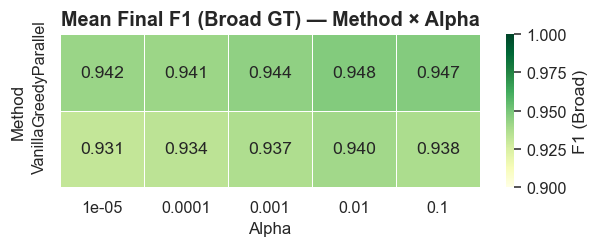

In [23]:
ag.plot_f1_heatmap(
    df_vanilla_final, df_greedy_final,
    GT=GT, greedy_label=greedy_label,
    dataset=DATASET, estimator=TARGET_ESTIMATOR,
    figures_dir=figures_dir,
)

## 12. Speed vs GT Quality Trade-off

Runtime vs final F1 (Broad). Point size ∝ N_Confirmed. Pentagon = GreedyParallel.

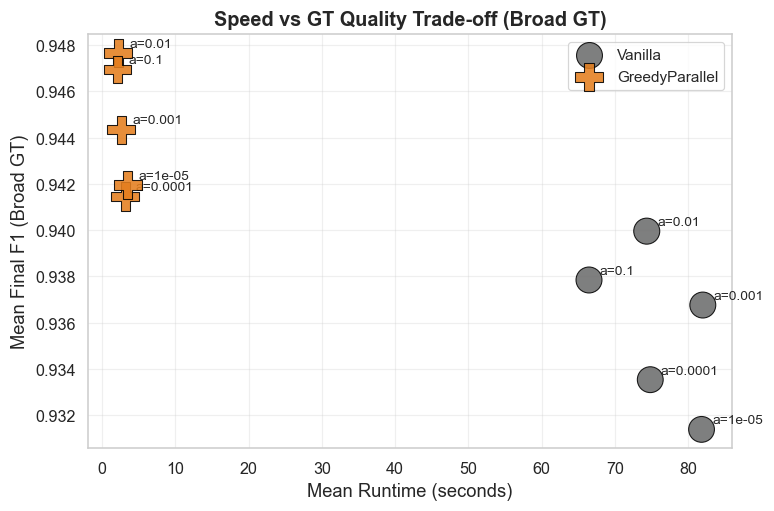

In [24]:
ag.plot_speed_vs_quality(
    df_vanilla_final, df_greedy_final, df_main,
    GT=GT, greedy_label=greedy_label,
    dataset=DATASET, estimator=TARGET_ESTIMATOR,
    figures_dir=figures_dir,
)

## 13. Effect of Alpha — Boxplots Across Runs

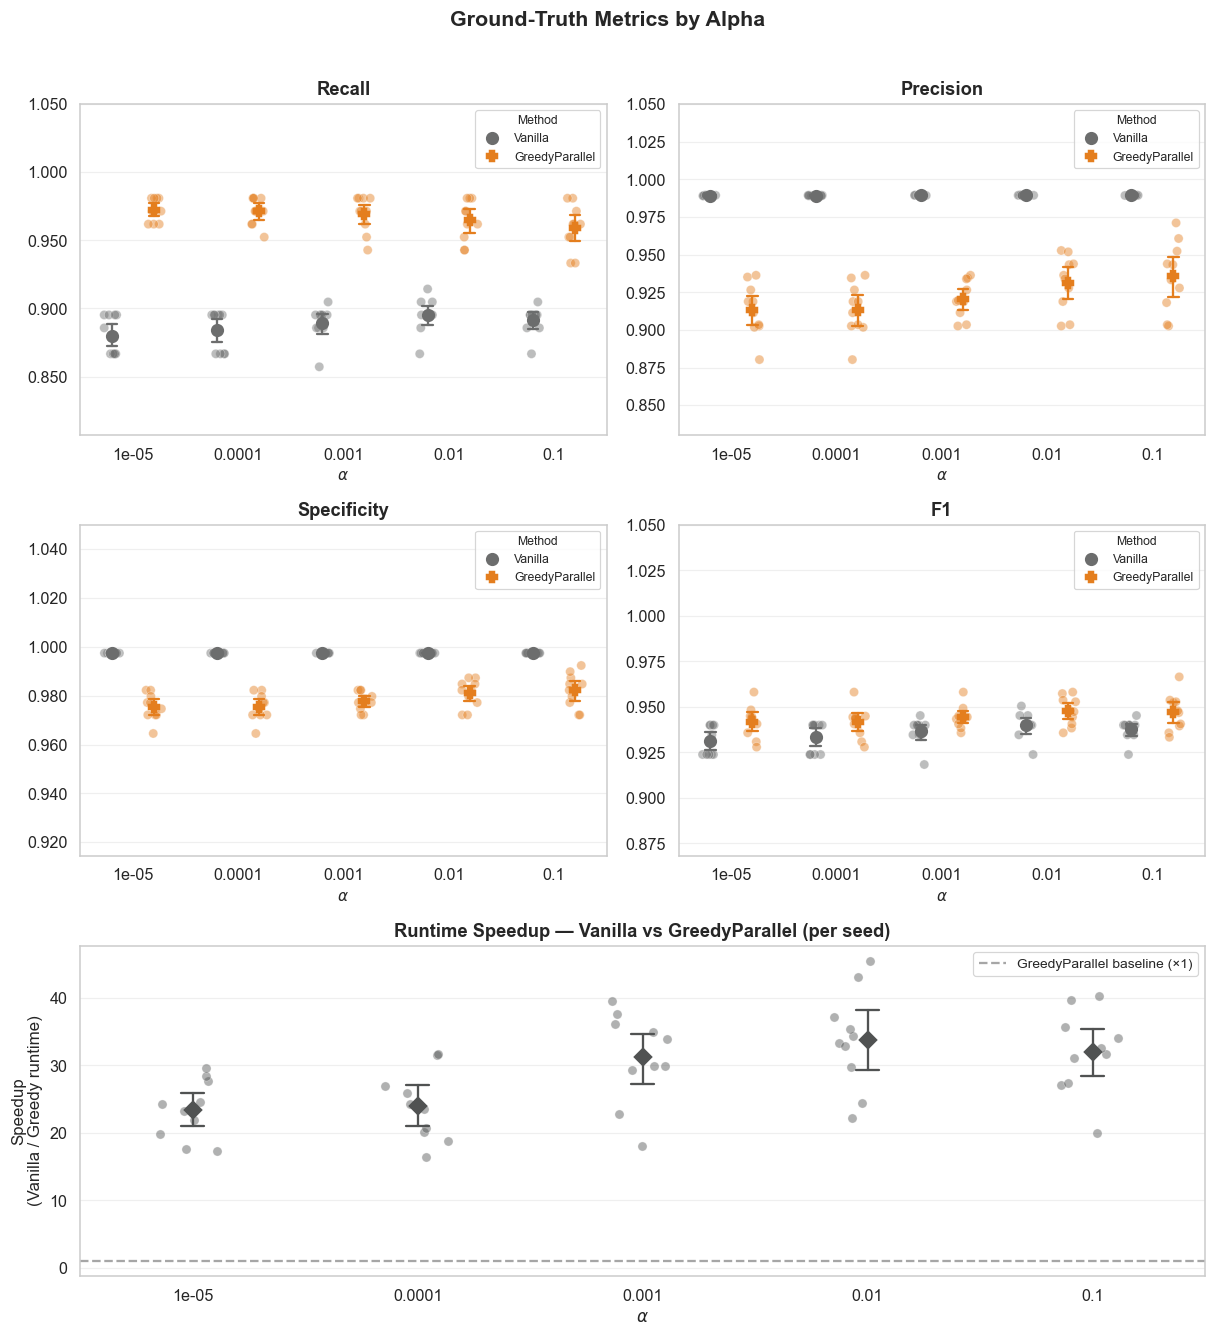

In [25]:
ag.plot_alpha_effect_boxplots(
    df_vanilla_final, df_greedy_final,
    alphas=alphas, GT=GT, greedy_label=greedy_label,
    dataset=DATASET, estimator=TARGET_ESTIMATOR,
    df_main=df_main, figures_dir=figures_dir,
)

## 14. Statistical Test: Greedy vs Vanilla (Broad GT)

Welch t-test on final-state metrics across runs.

In [26]:
df_tests = ag.run_statistical_tests(
    df_vanilla_final, df_greedy_final,
    alphas=alphas, GT=GT, greedy_label=greedy_label,
)

Statistical comparison — Broad GT (Welch t-test, significance = 0.05)
Columns: P_TwoSided (any diff) | P_Greedy>Vanilla (one-sided) | P_Vanilla>Greedy (one-sided)
--------------------------------------------------------------------------------------------------------------


,Metric,Alpha,Vanilla_Mean,Greedy_Mean,Diff (V-G),P_TwoSided,Sig_Two,P_Greedy>Vanilla,Sig_G>V,P_Vanilla>Greedy,Sig_V>G,Winner
0,Recall,1e-05,0.8800,0.9724,-0.0924,0.0000,***,0.0000,***,1.0000,ns,GreedyParallel
1,Recall,0.0001,0.8838,0.9714,-0.0876,0.0000,***,0.0000,***,1.0000,ns,GreedyParallel
2,Recall,0.001,0.8895,0.9695,-0.0800,0.0000,***,0.0000,***,1.0000,ns,GreedyParallel
3,Recall,0.01,0.8952,0.9648,-0.0695,0.0000,***,0.0000,***,1.0000,ns,GreedyParallel
4,Recall,0.1,0.8914,0.9590,-0.0676,0.0000,***,0.0000,***,1.0000,ns,GreedyParallel
5,Precision,1e-05,0.9893,0.9136,0.0757,0.0000,***,1.0000,ns,0.0000,***,Vanilla
6,Precision,0.0001,0.9893,0.9135,0.0758,0.0000,***,1.0000,ns,0.0000,***,Vanilla
7,Precision,0.001,0.9894,0.9207,0.0687,0.0000,***,1.0000,ns,0.0000,***,Vanilla
8,Precision,0.01,0.9895,0.9315,0.0579,0.0000,***,1.0000,ns,0.0000,***,Vanilla
9,Precision,0.1,0.9894,0.9357,0.0537,0.0000,***,1.0000,ns,0.0000,***,Vanilla


## 15. Mean Trajectory with Confidence Band (Vanilla)

Mean ± 1 std across runs. GreedyParallel shown as dashed reference ± shaded band.

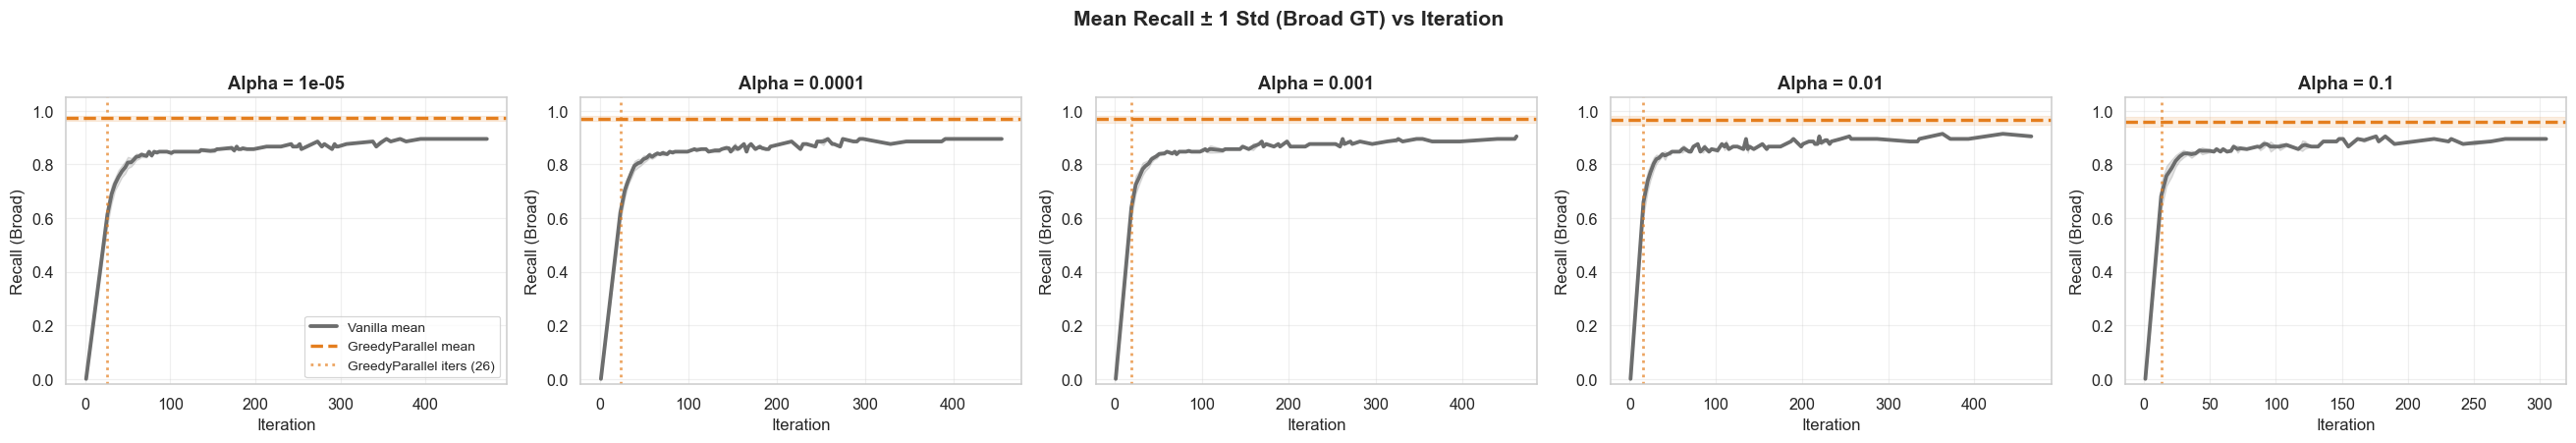

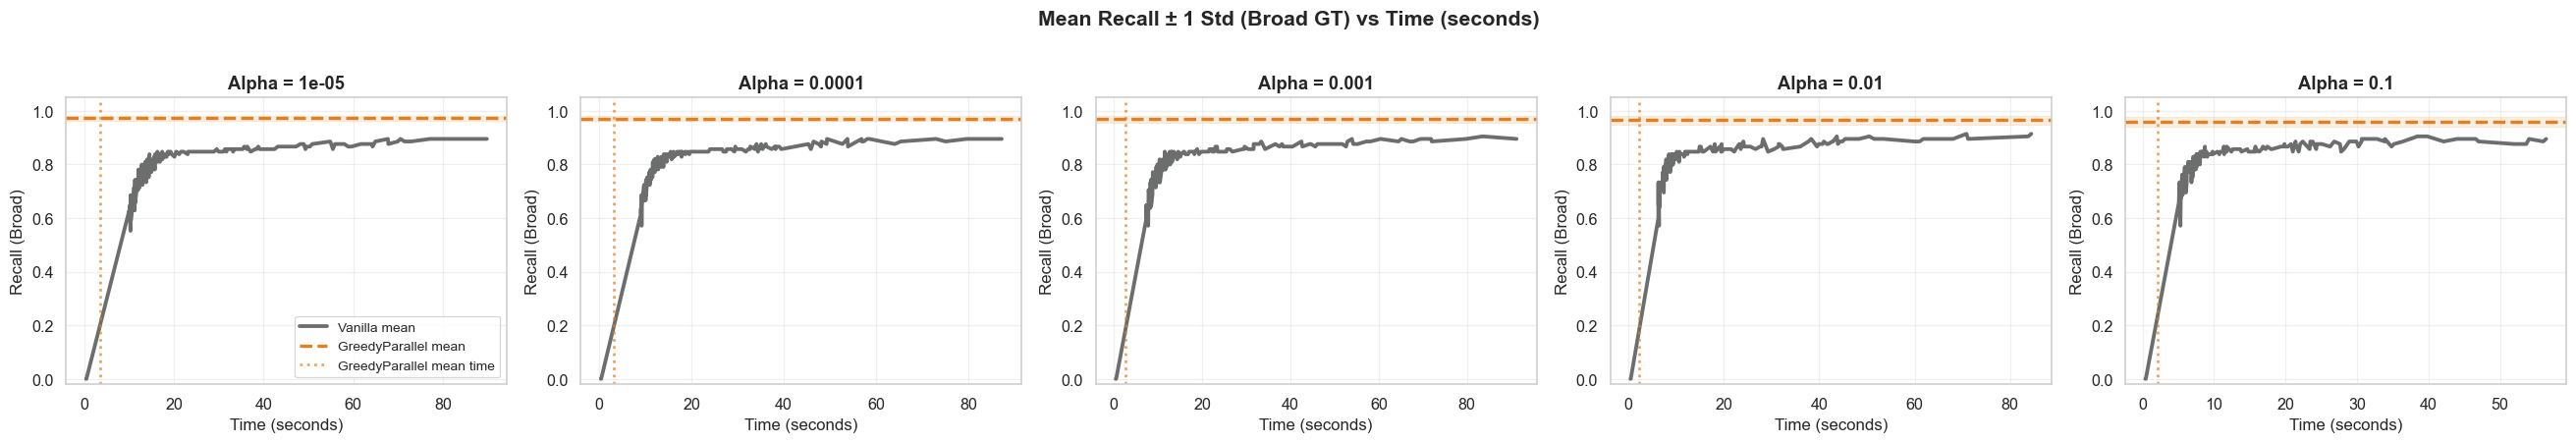

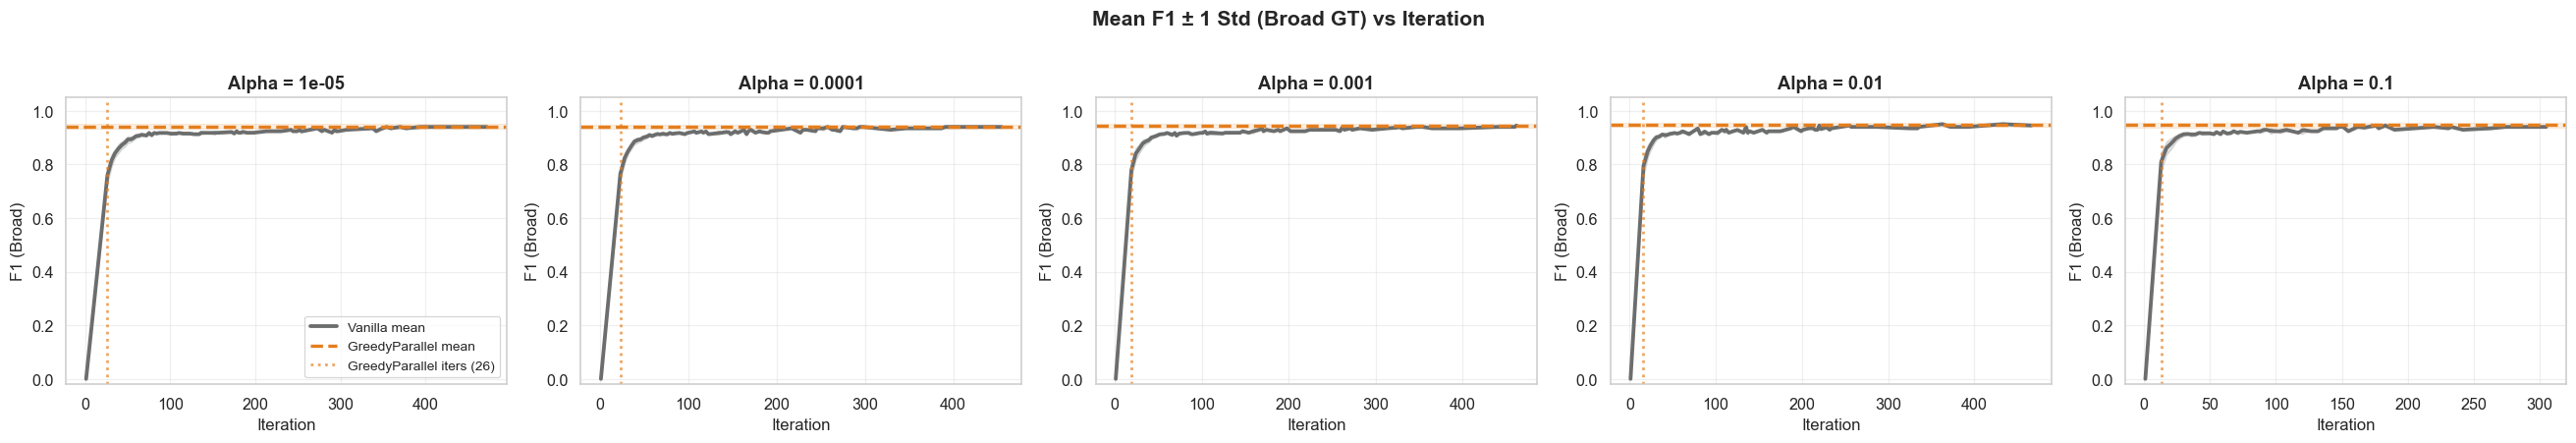

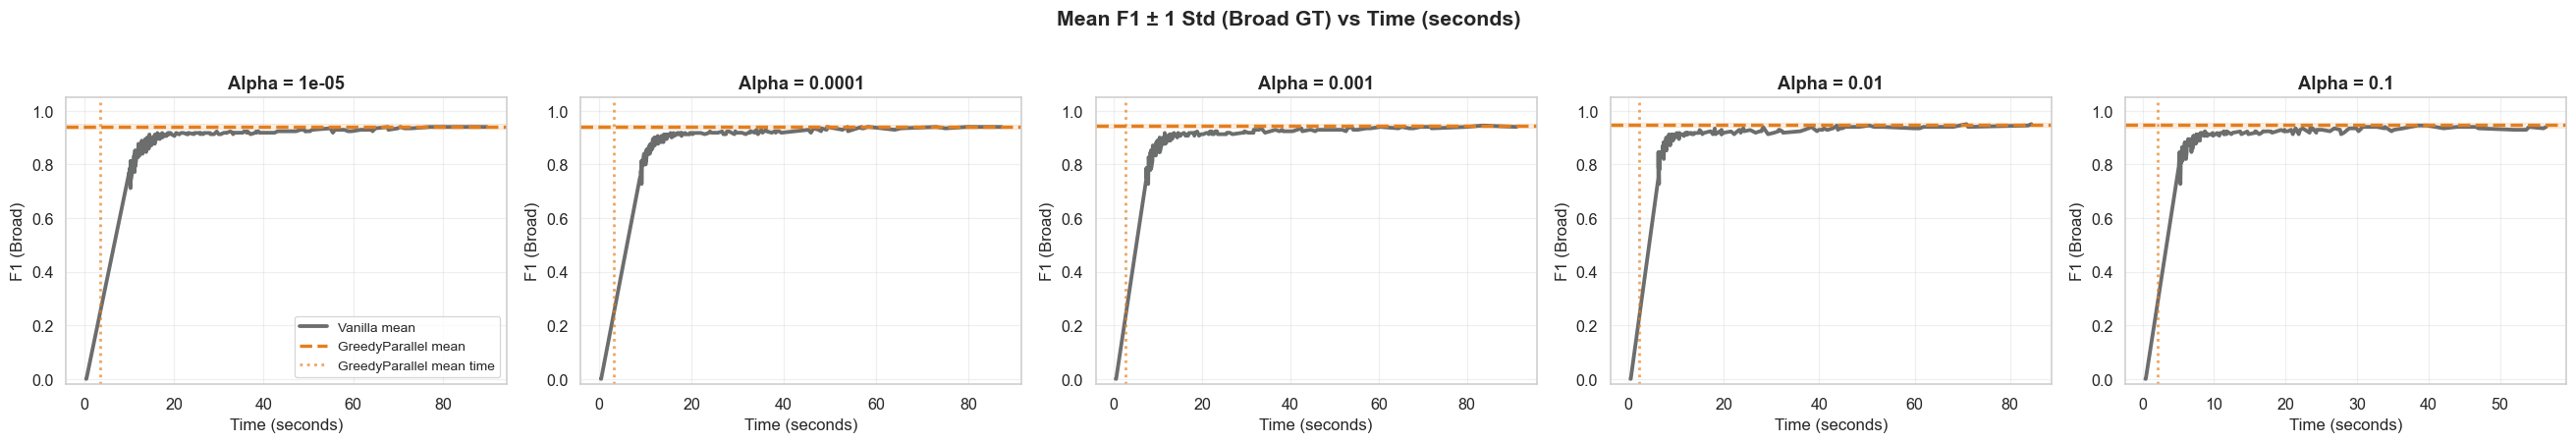

In [27]:
for metric in ['Recall', 'F1']:
    ag.plot_mean_trajectory_band(
        metric,
        df_vanilla=df_vanilla, df_greedy=df_greedy,
        alphas=alphas, n_features=n_features,
        GT=GT, greedy_label=greedy_label,
        dataset=DATASET, estimator=TARGET_ESTIMATOR,
        x_col='Iteration', x_label='Iteration',
        figures_dir=figures_dir,
    )
    ag.plot_mean_trajectory_band(
        metric,
        df_vanilla=df_vanilla, df_greedy=df_greedy,
        alphas=alphas, n_features=n_features,
        GT=GT, greedy_label=greedy_label,
        dataset=DATASET, estimator=TARGET_ESTIMATOR,
        x_col='Elapsed_Sec', x_label='Time (seconds)',
        figures_dir=figures_dir,
    )

## 15b. Mean Trajectory ± Band — Single Alpha

All four metrics for `FOCUS_ALPHA` in 2×2 grids, vs Iteration and vs Time.

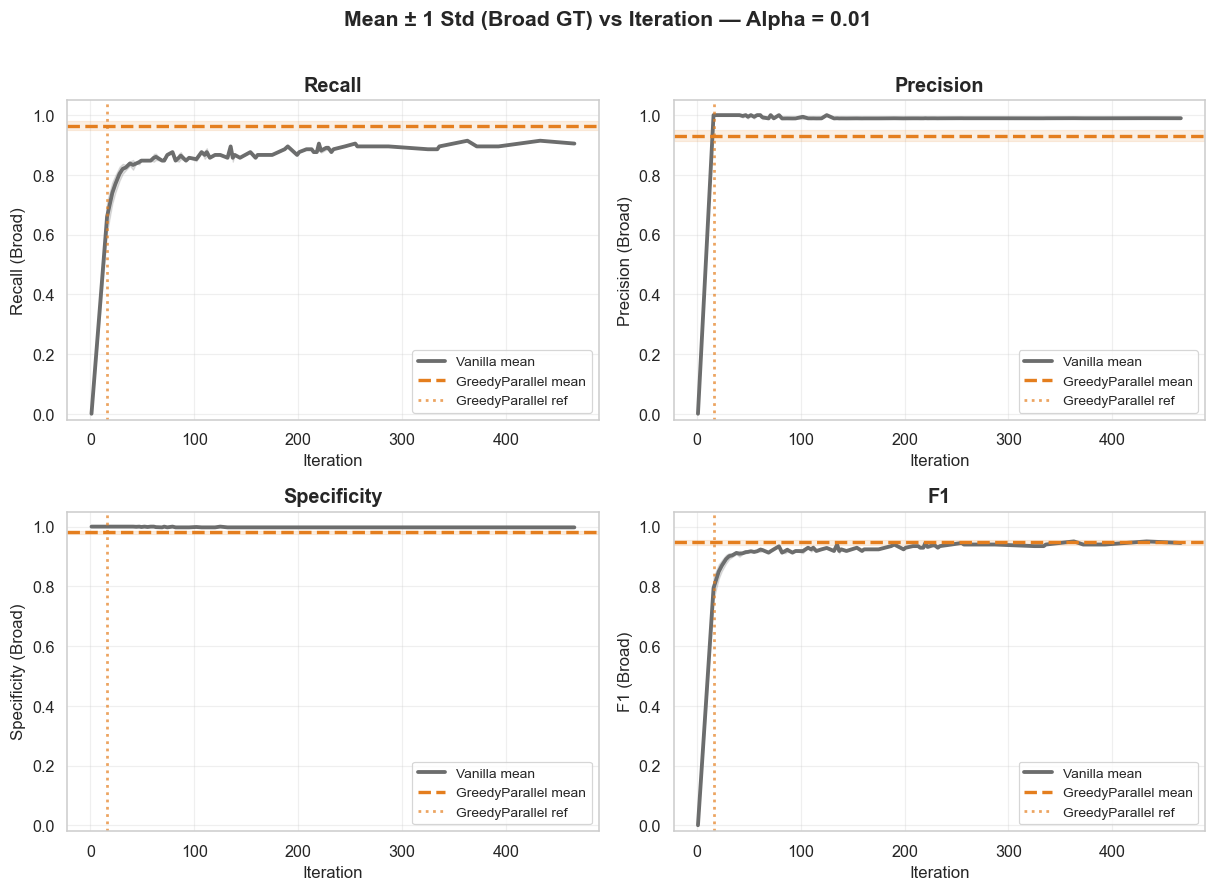

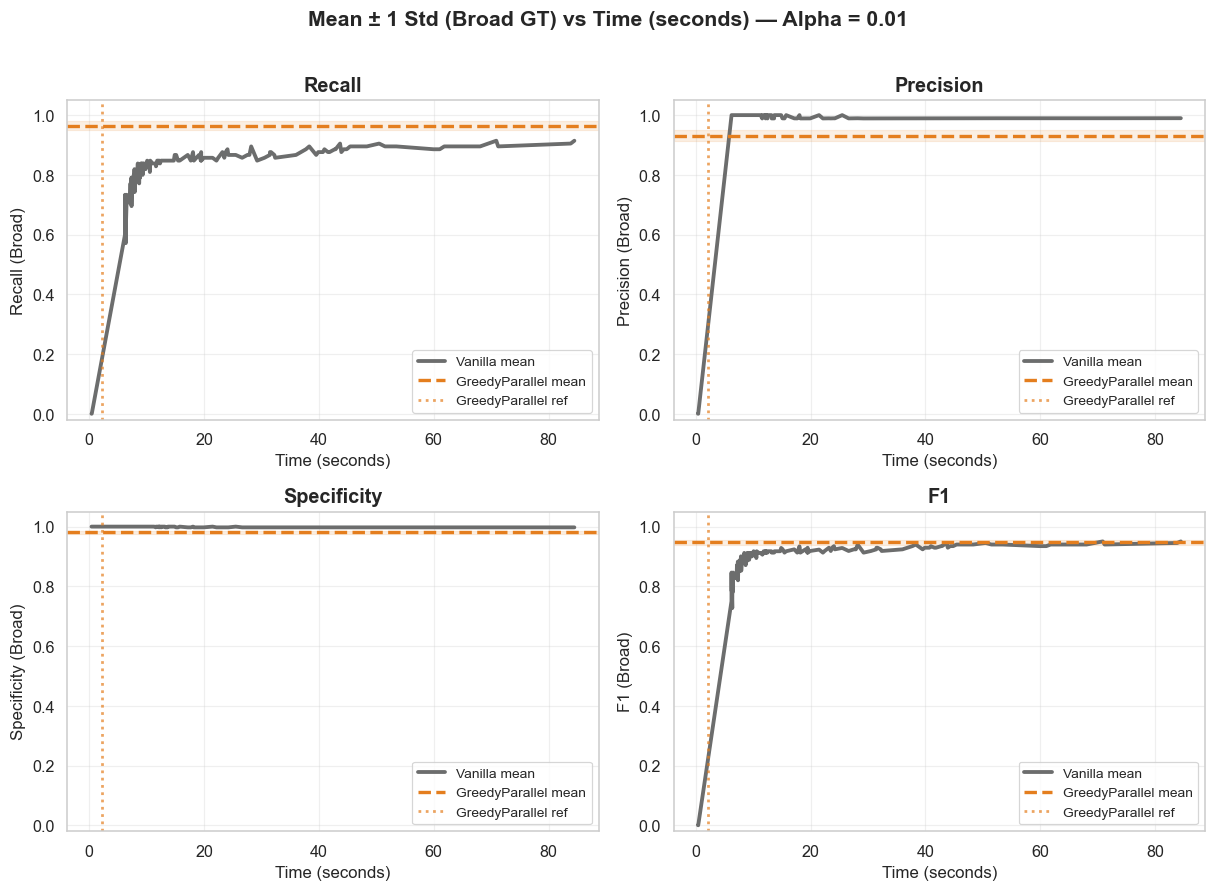

In [28]:
ag.plot_mean_trajectory_band_single_alpha(
    focus_alpha=FOCUS_ALPHA,
    df_vanilla=df_vanilla, df_greedy=df_greedy,
    n_features=n_features,
    GT=GT, greedy_label=greedy_label,
    dataset=DATASET, estimator=TARGET_ESTIMATOR,
    figures_dir=figures_dir,
)

## 16. Key Findings

In [29]:
ag.print_key_findings(
    df_vanilla_final, df_greedy_final, df_vanilla,
    alphas=alphas, GT=GT, gt_broad=gt_broad, n_features=n_features,
    greedy_label=greedy_label
)

KEY FINDINGS — SYNTHETIC GROUND TRUTH ANALYSIS (Broad GT)
GT definition: informative + redundant features (n=105 out of 500)

  Recall:
    alpha= 1e-05 | Vanilla: 0.880 ± 0.014  |  GreedyParallel: 0.972 ± 0.008
    alpha=0.0001 | Vanilla: 0.884 ± 0.015  |  GreedyParallel: 0.971 ± 0.010
    alpha= 0.001 | Vanilla: 0.890 ± 0.013  |  GreedyParallel: 0.970 ± 0.013
    alpha=  0.01 | Vanilla: 0.895 ± 0.013  |  GreedyParallel: 0.965 ± 0.015
    alpha=   0.1 | Vanilla: 0.891 ± 0.010  |  GreedyParallel: 0.959 ± 0.017

  Precision:
    alpha= 1e-05 | Vanilla: 0.989 ± 0.000  |  GreedyParallel: 0.914 ± 0.017
    alpha=0.0001 | Vanilla: 0.989 ± 0.000  |  GreedyParallel: 0.914 ± 0.017
    alpha= 0.001 | Vanilla: 0.989 ± 0.000  |  GreedyParallel: 0.921 ± 0.012
    alpha=  0.01 | Vanilla: 0.989 ± 0.000  |  GreedyParallel: 0.932 ± 0.018
    alpha=   0.1 | Vanilla: 0.989 ± 0.000  |  GreedyParallel: 0.936 ± 0.023

  Specificity:
    alpha= 1e-05 | Vanilla: 0.997 ± 0.000  |  GreedyParallel: 0.975 ± 0.00

## 17. Export

In [30]:
ag.export_results(
    df_tests=df_tests,
    df_final_summary=df_final_summary,
    tests_path='../data/synthetic_gt_statistical_tests.csv',
    summary_path='../data/synthetic_gt_final_summary.csv',
)

Exported:
  ../data/synthetic_gt_statistical_tests.csv
  ../data/synthetic_gt_final_summary.csv
